# jPCA on motor-cortex population data — the method, and what it means

This notebook reproduces, on synthetic data, the analysis of **Churchland et al. 2012
(*Nature*, "Neural population dynamics during reaching")** — the paper that made
"rotational dynamics" famous.

**The setup.** During a reaching task, hundreds of neurons in motor/premotor cortex are
recorded across several reach directions (conditions). Single neurons show complex,
multiphasic, condition-dependent responses — hard to read directly. jPCA asks a
collective question instead: *does the population state rotate through state space?*

**The pipeline** (each step matters — Notebook 2 shows how much):

1. firing rates per neuron per condition (Gaussian smoothing of spike trains),
2. soft-normalization per neuron (so high-rate neurons don't dominate),
3. subtract the cross-condition mean (focus on condition-dependent structure),
4. PCA to a handful of latent dimensions (Churchland used 6),
5. fit a linear dynamical system **dX/dt = M·X** in that subspace,
6. constrain **M to be skew-symmetric** (M = −Mᵀ) — a matrix that produces *purely
   rotational* flow — and read off the rotation planes from its eigenvalue pairs.

The skew-symmetry constraint is the whole trick: a skew-symmetric matrix has purely
imaginary eigenvalues ±iω, each conjugate pair defining one plane in which the state
rotates with frequency ω/2π. Nothing decays, nothing grows — rotation only.

rates (neurons, conditions, time): (150, 8, 120)


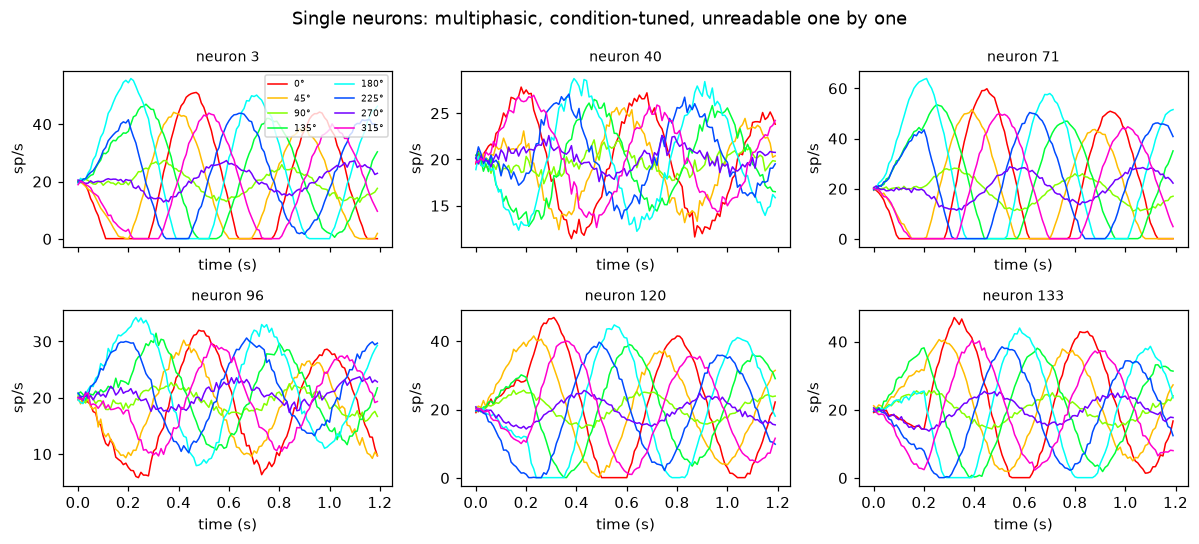

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from jpca_core import *
%matplotlib inline
plt.rcParams['figure.dpi'] = 110

# --- Generate Churchland-style synthetic data -------------------------------
# 8 reach directions; per condition, latent dynamics = a decaying 2 Hz oscillation
# (shared plane, condition-dependent radius) + 2 direction-tuned ramps.
# 150 neurons are random linear mixtures of these 4 latents.
rates, dirs, t = simulate_reaching(n_neurons=150, n_conditions=8, f_rot_hz=2.0)
print('rates (neurons, conditions, time):', rates.shape)

fig, axes = plt.subplots(2, 3, figsize=(11, 5), sharex=True)
colors = plt.cm.hsv(np.linspace(0, 1, rates.shape[1], endpoint=False))
for ax, u in zip(axes.flat, [3, 40, 71, 96, 120, 133]):
    for c in range(rates.shape[1]):
        ax.plot(t, rates[u, c], color=colors[c], lw=1)
    ax.set_title(f'neuron {u}', fontsize=9)
    ax.set_xlabel('time (s)'); ax.set_ylabel('sp/s')
axes.flat[0].legend([f'{int(np.degrees(d))}°' for d in dirs], fontsize=6, ncol=2)
fig.suptitle('Single neurons: multiphasic, condition-tuned, unreadable one by one')
fig.tight_layout(); plt.show()

**What single neurons look like.** Each neuron mixes the latents: some show the
oscillation, some the ramps, most a blend. No single neuron "rotates." Rotation, if it
exists, is a property of the population state X(t) — the vector of all neurons at once.

Now run the preprocessing. The next cell walks through the three steps one at a time,
so you can see exactly what each one does, before applying them in a single call.
Note that every choice here (smoothing width, the +5 sp/s normalization constant,
subtracting the condition mean) *shapes what the rotation will look like later*.
Kuzmina et al. 2024 showed that a 10→20 ms change in smoothing can flip a dataset
from "rotating" to "not rotating." Treat these as hypotheses, not defaults.

per-neuron range before normalization: 6.7 .. 62.2 sp/s
neuron 71: range 62.2 sp/s  ->  0.93 after normalization
neuron 0: range 6.7 sp/s  ->  0.57 after normalization
the +5 sp/s "soft" constant: without it neuron 0 would be scaled up 9.3x more than neuron 71; with it, only 5.7x


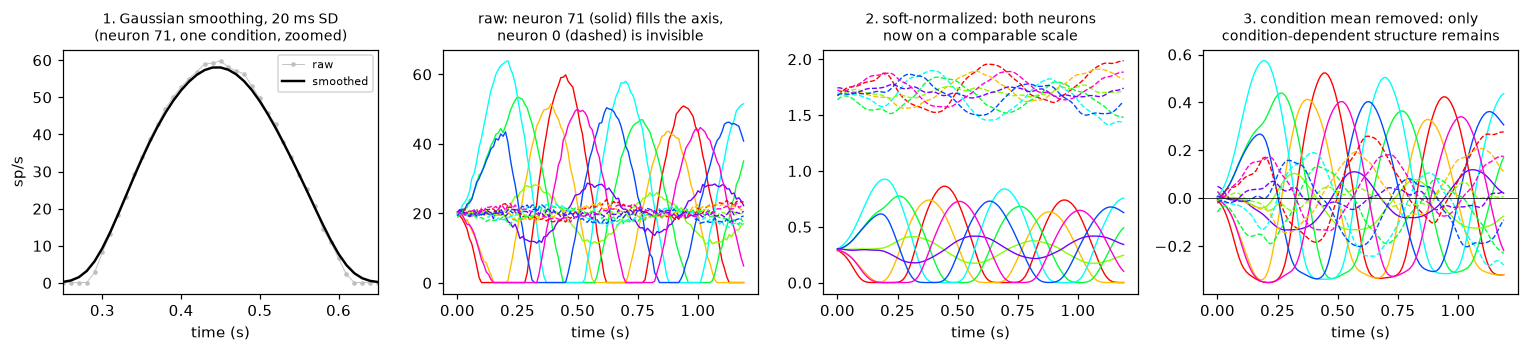

check: step-by-step == preprocess(): True


In [2]:
# --- What each preprocessing step does, before -> after ---------------------
from scipy.ndimage import gaussian_filter1d

smoothed = gaussian_filter1d(rates, 20 / 10, axis=2, mode='nearest')   # 1. smooth in time
spread = smoothed.max(axis=(1, 2)) - smoothed.min(axis=(1, 2))         # per-neuron range
normed = smoothed / (spread + 5.0)[:, None, None]                      # 2. soft-normalize
final = normed - normed.mean(axis=1, keepdims=True)                    # 3. subtract condition mean

hi, lo = int(np.argmax(spread)), int(np.argmin(spread))   # most / least modulated neuron
print(f'per-neuron range before normalization: {spread.min():.1f} .. {spread.max():.1f} sp/s')
print(f'neuron {hi}: range {spread[hi]:.1f} sp/s  ->  {np.ptp(normed[hi]):.2f} after normalization')
print(f'neuron {lo}: range {spread[lo]:.1f} sp/s  ->  {np.ptp(normed[lo]):.2f} after normalization')
print(f'the +5 sp/s "soft" constant: without it neuron {lo} would be scaled up '
      f'{spread[hi] / spread[lo]:.1f}x more than neuron {hi}; with it, only '
      f'{(spread[hi] + 5) / (spread[lo] + 5):.1f}x')

fig, axes = plt.subplots(1, 4, figsize=(14, 3.3))
c0 = 0
axes[0].plot(t, rates[hi, c0], 'o-', color='0.75', ms=2, lw=0.6, label='raw')
axes[0].plot(t, smoothed[hi, c0], color='k', lw=1.6, label='smoothed')
axes[0].set_xlim(0.25, 0.65)
axes[0].set_title(f'1. Gaussian smoothing, 20 ms SD\n(neuron {hi}, one condition, zoomed)',
                  fontsize=9)
axes[0].legend(fontsize=7); axes[0].set_ylabel('sp/s')

for u, ls in [(hi, '-'), (lo, '--')]:
    for c in range(rates.shape[1]):
        axes[1].plot(t, rates[u, c], color=colors[c], lw=0.9, ls=ls)
        axes[2].plot(t, normed[u, c], color=colors[c], lw=0.9, ls=ls)
        axes[3].plot(t, final[u, c], color=colors[c], lw=0.9, ls=ls)
axes[1].set_title(f'raw: neuron {hi} (solid) fills the axis,\nneuron {lo} (dashed) is invisible',
                  fontsize=9)
axes[2].set_title('2. soft-normalized: both neurons\nnow on a comparable scale', fontsize=9)
axes[3].axhline(0, color='k', lw=0.5)
axes[3].set_title('3. condition mean removed: only\ncondition-dependent structure remains', fontsize=9)
for ax in axes:
    ax.set_xlabel('time (s)')
fig.tight_layout(); plt.show()

rates_p = preprocess(rates, bin_ms=10, smooth_sd_ms=20)   # all three steps in one call
print('check: step-by-step == preprocess():', np.allclose(final, rates_p))

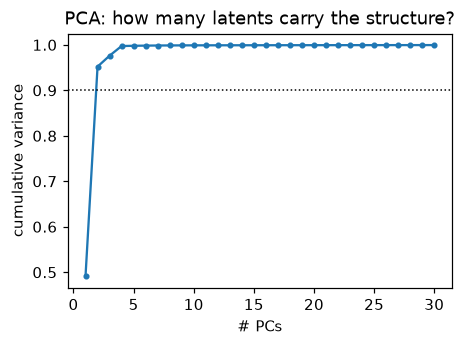

variance captured by 6 PCs: 1.00


In [3]:
from sklearn.decomposition import PCA
X = stack_conditions(rates_p)                     # (N, C*T)
pca_full = PCA().fit(X.T)
cum = np.cumsum(pca_full.explained_variance_ratio_)
plt.figure(figsize=(4.5, 3))
plt.plot(np.arange(1, 31), cum[:30], 'o-', ms=3)
plt.axhline(0.9, color='k', ls=':', lw=1)
plt.xlabel('# PCs'); plt.ylabel('cumulative variance')
plt.title('PCA: how many latents carry the structure?'); plt.show()
print('variance captured by 6 PCs: %.2f' % cum[5])

**The jPCA step, mathematically.** After PCA we have reduced trajectories Z(t) in a
6-D latent space. We fit the best linear flow:

> dZ/dt ≈ M·Z by least squares → M_full = dZ·Z⁺

then keep only the rotational part of the flow. The closed-form projection

> M_skew = (M_full − M_fullᵀ) / 2

is the initialization; the original toolbox (and our `jpca()` by default,
`refine_skew=True`) then refines it by minimizing **‖dZ − M·Z‖² directly over
skew-symmetric matrices** (conjugate gradients — the same constrained fit as
the 2012 MATLAB code). We quantify the rotational fit with
R² = 1 − ‖dZ − M_skew·Z‖² / ‖dZ‖².

Eigendecomposing M_skew yields imaginary-conjugate pairs ±iω. Each pair's eigenvector
v = a + ib defines a rotation plane span{a, b} — the "jPC planes." Projecting the data
into those planes is what produces the famous figure. (For display, the basis within
each plane is rotated so the initial — preparatory — states lie along jPC1; this is
purely cosmetic and changes no variances or fits.)

**A metric subtlety Churchland's figures hide:** the whole-space R² measures how well
rotation explains the derivative across *all six* latent dimensions — including
non-rotational ones (the direction-tuned ramps are translational, not rotational, so
their derivative cannot be fit by any skew-symmetric M). The field's actual claim rests
on the *top rotation planes*: how much variance they capture and how well rotation fits
*within* them. We report both below.

whole-space skew-symmetric fit R^2 = 0.581  (diluted by the ramp dimensions)
plane frequencies (Hz): [1.78 0.65 0.  ]
jPC plane 1: 95.3% of variance | in-plane rotation R^2 = +0.62 | 1.78 Hz
jPC plane 2:  4.6% of variance | in-plane rotation R^2 = +0.00 | 0.65 Hz
jPC plane 3:  0.1% of variance | in-plane rotation R^2 = +0.04 | 0.00 Hz


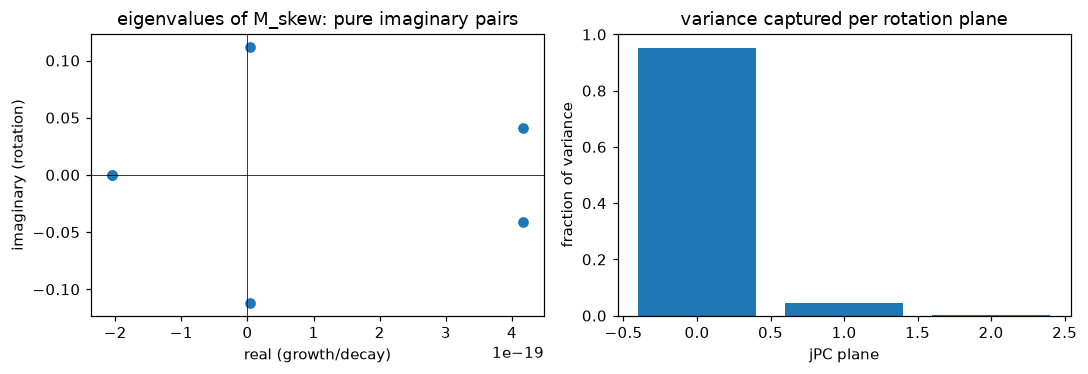

In [4]:
res = jpca(rates_p, n_pcs=6, dt_s=0.01)
print('whole-space skew-symmetric fit R^2 = %.3f  (diluted by the ramp dimensions)' % res['r2'])
print('plane frequencies (Hz):', np.round(res['freqs_hz'], 2))

projs = project_planes(res)
for k, (_, frac, r2p) in enumerate(projs, 1):
    print('jPC plane %d: %4.1f%% of variance | in-plane rotation R^2 = %+.2f | %.2f Hz'
          % (k, 100 * frac, r2p, res['freqs_hz'][k - 1]))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
ev = res['eigvals']
axes[0].plot(ev.real, ev.imag, 'o')
axes[0].axhline(0, color='k', lw=0.5); axes[0].axvline(0, color='k', lw=0.5)
axes[0].set_xlabel('real (growth/decay)'); axes[0].set_ylabel('imaginary (rotation)')
axes[0].set_title('eigenvalues of M_skew: pure imaginary pairs')
axes[1].bar(range(len(projs)), [p[1] for p in projs])
axes[1].set_xlabel('jPC plane'); axes[1].set_ylabel('fraction of variance')
axes[1].set_title('variance captured per rotation plane')
fig.tight_layout(); plt.show()

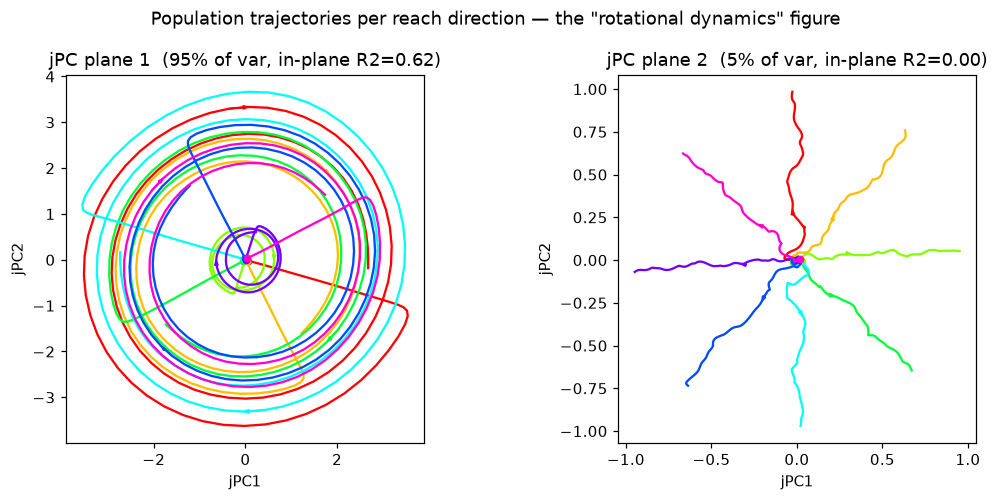

In [5]:
# --- The classic figure: trajectories in the top two jPC planes -------------
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, (coords, frac, r2p), k in zip(axes, projs, [1, 2]):
    for c in range(rates_p.shape[1]):
        ax.plot(coords[0, c], coords[1, c], color=colors[c], lw=1.5)
        ax.plot(coords[0, c, 0], coords[1, c, 0], 'o', color=colors[c], ms=4)
        # arrowhead mid-trajectory to show the common rotation direction
        i = int(coords.shape[2] * 0.45)
        dx = coords[0, c, i+1] - coords[0, c, i]; dy = coords[1, c, i+1] - coords[1, c, i]
        ax.arrow(coords[0, c, i], coords[1, c, i], dx, dy, color=colors[c],
                 head_width=0.02*np.abs(coords).max(), length_includes_head=True)
    ax.set_title(f'jPC plane {k}  ({frac:.0%} of var, in-plane R2={r2p:.2f})')
    ax.set_xlabel('jPC1'); ax.set_ylabel('jPC2'); ax.set_aspect('equal')
fig.suptitle('Population trajectories per reach direction — the "rotational dynamics" figure')
fig.tight_layout(); plt.show()

## What it means — and what it does not mean

**What the plot shows:** the population state moves through a *quadrature pair* of latent
patterns — pattern A, then pattern B (90° later), then −A, then −B. Every condition does
this in the same direction, at a condition-dependent radius. Churchland's interpretation:
motor cortex is a **pattern generator** — the rotation is the dynamical machinery that
produces time-varying muscle commands (position + velocity must both be represented, and
"variable + its derivative" plotted in state space *is* a rotation; that part is nearly
kinematically inevitable).

**What the plot does *not* show:**

- **Stability or attractor-ness.** These are transient, driven trajectories — the state
  passes through the rotation once and leaves. Nothing here says the rotation recovers
  from a perturbation. (Churchland et al. never claimed an attractor; later work —
  Sussillo 2015, Michaels 2016, Lebedev 2019 — showed rotations arise without one.)
- **Uniqueness of mechanism.** jPCA *maximizes* rotation by construction — it searches
  for the most rotational view of the data. So the plot's existence is not evidence;
  the evidence is the fit *relative to shuffles/surrogate data*, and whether the rotation
  plane/frequency mean anything physically.
- **Even the R² needs reading.** Whole-space and in-plane R² answer different questions;
  a dataset can be "rotational" in its top planes while its bulk flow is not.
- **Physical location.** jPCA lives entirely in latent space. It says nothing about where
  in the brain the quadrature pair sits, or whether the rotation corresponds to anything
  spatial — which is the opening Notebook 2 exploits.

**Next:** Lebedev's doubt. If neurons simply fire one after another, jPCA will show you
a rotation — no dynamical machinery required. → Notebook 2.